# EDA: Hinglish offensive-content classifier

Exploratory analysis of the TRAC-1 Hindi data. **Counts, shares and charts only: no raw comments are printed or saved**, so everything this notebook writes under `reports/` is safe to commit.

**Rules this notebook follows**
- Train and dev are explored in full (text, labels, language mix).
- The two test sets are used for **inputs only** (length, script, vocabulary, formatting). Their labels are dropped at load time. The one exception is the last section, which compares saved model *predictions* with the base rate.
- Nothing here changes a model, a threshold or a split.

**Run order:** first `python src/langmix.py --split train` (and `fb_test`, `tw_test`; `dev` already exists), then run all cells top to bottom. Outputs: `reports/figures/*.png`, `reports/eda/*.csv`, `reports/eda_summary.md`.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import re
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from preprocess import NORM_GROUPS, MENTION_RE, REPEAT_RE, URL_RE, clean_text, load_frozen_split
from langmix import script_class, words_of

FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B50\u2764]")
NAMES = {"train": "Train", "dev": "Dev", "fb_test": "FB test", "tw_test": "Twitter test"}
COLORS = {"train": "#4c72b0", "dev": "#55a868", "fb_test": "#dd8452", "tw_test": "#c44e52"}
tables = {}          # name -> DataFrame, written to reports/eda_summary.md at the end


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 0. Load the frozen splits

In [2]:
raw = {k: load_frozen_split(k) for k in NAMES}
for k in ("fb_test", "tw_test"):                       # test labels are never used in this notebook
    raw[k] = raw[k].drop(columns=["label", "label3"])
pd.DataFrame({"split": [NAMES[k] for k in raw], "rows": [len(v) for v in raw.values()]})

,split,rows
0,Train,11556
1,Dev,2812
2,FB test,970
3,Twitter test,1194


Per-comment features, computed once for all four splits. A comment is flagged for a feature if it contains it at least once.

In [3]:
HASHTAG_RE = re.compile(r"#\S+")


def body_script(text):
    # Script of the comment body only. script_class(clean_text(t)) counts the letters of the [URL] and [USER]
    # placeholders and of Latin hashtags as Latin, which makes Devanagari tweets look "mixed".
    t = URL_RE.sub(" ", text)
    t = MENTION_RE.sub(" ", t)
    t = HASHTAG_RE.sub(" ", t)
    return script_class(clean_text(t))


def features(df):
    flag = lambda rx: df["text"].map(lambda t: bool(rx.search(t)))
    clean = df["text"].map(clean_text)
    letters = df["text"].map(lambda t: [c for c in t if c.isascii() and c.isalpha()])
    f = pd.DataFrame({"id": df["id"].values})
    f["words"] = df["text"].str.split().str.len().values
    f["chars"] = df["text"].str.len().values
    f["script"] = clean.map(script_class).values               # exactly what the model pipeline sees
    f["script_body"] = df["text"].map(body_script).values       # ignores #hashtags, @mentions and links
    f["hashtag"] = df["text"].str.contains("#", regex=False).values
    f["mention"] = flag(MENTION_RE).values
    f["url"] = flag(URL_RE).values
    f["emoji"] = flag(EMOJI).values
    f["repeat"] = flag(REPEAT_RE).values                       # e.g. 'sooooo'
    f["caps_share"] = letters.map(lambda ls: np.mean([c.isupper() for c in ls]) if ls else np.nan).values
    for col in ("label", "label3"):
        if col in df:
            f[col] = df[col].values
    return f


feats = {k: features(raw[k]) for k in raw}
feats["train"].head(3).drop(columns=["id"])

,words,chars,script,script_body,hashtag,mention,url,emoji,repeat,caps_share,label,label3
0,22,103,roman,roman,False,False,False,True,False,0.062500,1,OAG
1,16,76,roman,roman,False,False,False,False,False,0.016949,1,CAG
2,26,126,roman,roman,False,False,False,False,False,0.000000,1,CAG


## 1. Class balance

The task is binary (NAG = 0, OAG + CAG = 1), but the original three classes show where the imbalance comes from.

label3,OAG,CAG,NAG
Train,4760,4683,2113
Dev,1169,1168,475


label3,OAG,CAG,NAG,aggressive (OAG+CAG)
Train,41.2,40.5,18.3,81.7
Dev,41.6,41.5,16.9,83.1


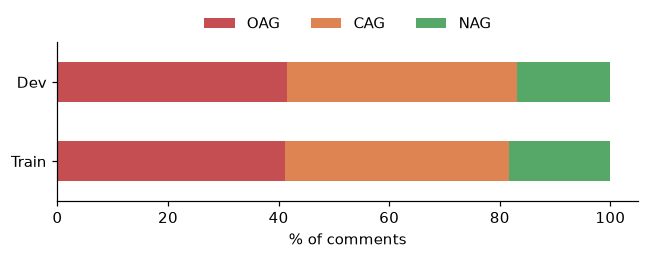

In [4]:
lab3 = pd.DataFrame({NAMES[k]: feats[k]["label3"].value_counts() for k in ("train", "dev")}).T[["OAG", "CAG", "NAG"]]
share3 = (lab3.div(lab3.sum(axis=1), axis=0) * 100).round(1)
share3["aggressive (OAG+CAG)"] = (share3["OAG"] + share3["CAG"]).round(1)
tables["Class balance (% of rows)"] = share3.reset_index().rename(columns={"index": "split"})
display(lab3), display(share3)

fig, ax = plt.subplots(figsize=(6, 2.6))
share3[["OAG", "CAG", "NAG"]].plot.barh(stacked=True, ax=ax, color=["#c44e52", "#dd8452", "#55a868"])
ax.set_xlabel("% of comments"), ax.set_ylabel("")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.25))
save("01_class_balance")

**Read:** about 82% of comments are aggressive, so always answering "aggressive" scores about 82% accuracy. This is why macro-F1 is the headline metric. CAG (covert) is as common as OAG (overt) and, per the manual audit, is the noisiest label.

## 2. Comment length

,split,p10,median,p90,p99,% <=10 words,% >40 words
0,Train,6.0,16.0,49.0,195.9,23.8,13.7
1,Dev,6.0,17.0,46.0,160.9,22.9,13.2
2,FB test,11.0,20.0,70.1,307.9,8.2,19.9
3,Twitter test,8.0,17.0,25.0,30.0,19.0,0.0


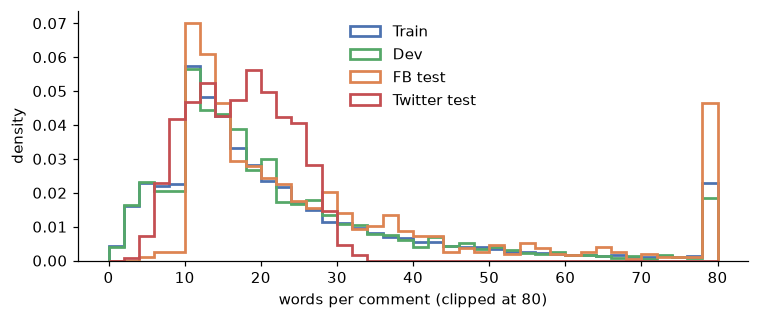

In [5]:
rows = []
for k, f in feats.items():
    w = f["words"]
    rows.append({"split": NAMES[k], "p10": w.quantile(.1), "median": w.median(), "p90": w.quantile(.9),
                 "p99": w.quantile(.99), "% <=10 words": 100 * (w <= 10).mean(), "% >40 words": 100 * (w > 40).mean()})
length_tbl = pd.DataFrame(rows).round(1)
tables["Length in words"] = length_tbl
display(length_tbl)

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, 81, 2)
for k, f in feats.items():
    ax.hist(f["words"].clip(upper=80), bins=bins, density=True, histtype="step", lw=1.8, color=COLORS[k], label=NAMES[k])
ax.set_xlabel("words per comment (clipped at 80)"), ax.set_ylabel("density"), ax.legend(frameon=False)
save("02_length_hist")

,rows,aggressive_pct
len_bin,,
1-5,1251,54.7
6-10,2142,77.7
11-20,5494,85.3
21-40,3523,87.4
>40,1958,85.0


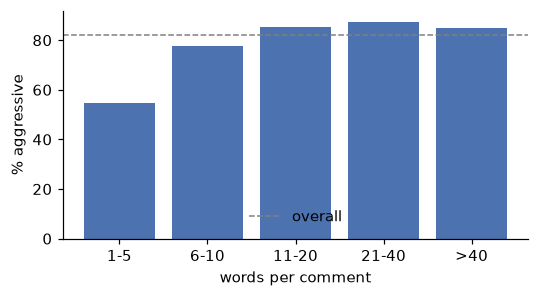

In [6]:
# Does length relate to the label? (train + dev only)
trdev = pd.concat([feats["train"], feats["dev"]])
trdev["len_bin"] = pd.cut(trdev["words"], [-1, 5, 10, 20, 40, 10_000], labels=["1-5", "6-10", "11-20", "21-40", ">40"])
by_len = trdev.groupby("len_bin", observed=True)["label"].agg(rows="size", aggressive_pct=lambda s: 100 * s.mean()).round(1)
tables["Aggressive share by length (train+dev)"] = by_len.reset_index()
display(by_len)

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(by_len.index.astype(str), by_len["aggressive_pct"], color="#4c72b0")
ax.axhline(100 * trdev["label"].mean(), color="grey", ls="--", lw=1, label="overall")
ax.set_xlabel("words per comment"), ax.set_ylabel("% aggressive"), ax.legend(frameon=False)
save("02_aggressive_by_length")

In [7]:
# Token length under the HingBERT tokenizer: how many comments are cut at max_len = 128?
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("l3cube-pune/hing-mbert-mixed")
    ids = tok(raw["train"]["text"].map(clean_text).tolist(), truncation=False)["input_ids"]
    tl = np.array([len(i) for i in ids])
    print(f"token length p50/p90/p99 = {int(np.percentile(tl,50))}/{int(np.percentile(tl,90))}/{int(np.percentile(tl,99))}; "
          f"cut at 128: {100*(tl>128).mean():.1f}%, cut at 64: {100*(tl>64).mean():.1f}%")
except Exception as e:
    print("tokenizer not available, skipped:", type(e).__name__)

d:\Projects\Hinglish Offensive-Content Classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (633 > 512). Running this sequence through the model will result in indexing errors


token length p50/p90/p99 = 32/93/380; cut at 128: 5.7%, cut at 64: 18.2%


**Read:** most comments are short, and short comments are *less* aggressive (the model is also weakest on them: higher error rate in the dev error analysis). The token-length check backs the ablation result that max length 64 vs 128 vs 256 made no measurable difference.

## 3. Script (Roman vs Devanagari)

Comment body only (hashtags, mentions and links ignored):


script_body,roman,devanagari,mixed,neither
Train,75.4,21.2,3.4,0.0
Dev,75.9,21.2,3.0,0.0
FB test,67.8,24.2,7.8,0.1
Twitter test,40.6,43.5,15.9,0.0


As the model pipeline sees it (placeholders and hashtags count as Latin letters):


script,roman,devanagari,mixed,neither
Train,75.4,19.8,4.8,0.0
Dev,75.9,19.9,4.2,0.0
FB test,67.8,24.1,8.0,0.0
Twitter test,40.0,0.0,60.0,0.0


,rows,aggressive_pct
script_body,,
devanagari,3044,75.7
mixed,478,58.4
neither,2,50.0
roman,10844,84.8


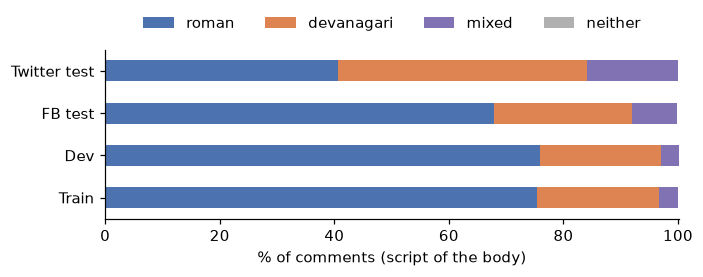

In [8]:
def script_table(col):
    t = pd.DataFrame({NAMES[k]: f[col].value_counts(normalize=True) * 100 for k, f in feats.items()}).T
    return t.reindex(columns=["roman", "devanagari", "mixed", "neither"]).fillna(0).round(1)


script_tbl = script_table("script_body")
tables["Script share of the comment body (% of comments)"] = script_tbl.reset_index().rename(columns={"index": "split"})
print("Comment body only (hashtags, mentions and links ignored):")
display(script_tbl)
print("As the model pipeline sees it (placeholders and hashtags count as Latin letters):")
display(script_table("script"))

trdev = pd.concat([feats["train"], feats["dev"]])
by_script = trdev.groupby("script_body")["label"].agg(rows="size", aggressive_pct=lambda s: 100 * s.mean()).round(1)
tables["Aggressive share by script of the body (train+dev)"] = by_script.reset_index()
display(by_script)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
script_tbl[["roman", "devanagari", "mixed", "neither"]].plot.barh(stacked=True, ax=ax,
    color=["#4c72b0", "#dd8452", "#8172b3", "#b0b0b0"])
ax.set_xlabel("% of comments (script of the body)"), ax.set_ylabel("")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.28))
save("03_script_share")

**Read:** Roman script dominates; Devanagari is about a fifth of the training data and is *less* aggressive than Roman. The two script tables differ mainly on Twitter, where nearly every tweet carries a hashtag, mention or link whose Latin letters the pipeline-style classifier counts; the body-only table is the fair one for comparing platforms. The ablation showed that dropping Devanagari training rows hurts, even though they are the minority.

## 4. Language mix (HingBERT-LID)

Needs `splits/langmix_<split>.csv` for each split. Mix is the share of Hindi words per comment; buckets are mostly-Hindi (>= 70%), balanced, mostly-English (<= 30%), and too-few-words.

mix_bucket,mostly-Hindi,balanced,mostly-English,too-few-words
Train,83.4,13.7,0.4,2.5
Dev,83.2,13.9,0.4,2.5
FB test,87.7,11.9,0.4,0.0
Twitter test,90.1,9.5,0.3,0.2


,rows,aggressive_pct
mix_bucket,,
mostly-Hindi,11975,83.8
balanced,1972,78.2
mostly-English,64,65.6
too-few-words,357,45.4


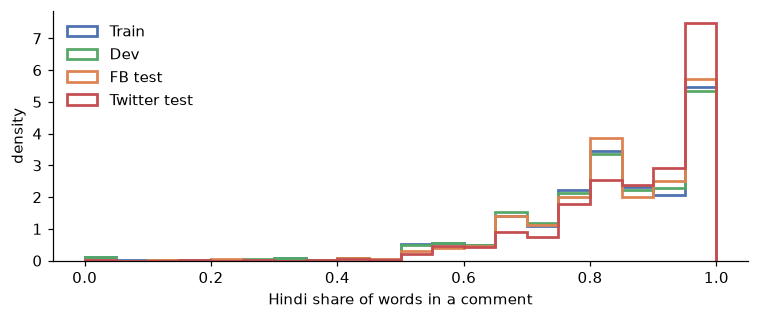

In [9]:
have_mix = True
for k in feats:
    p = ROOT / "splits" / f"langmix_{k}.csv"
    if p.exists():
        m = pd.read_csv(p)[["id", "hi_share", "mix_bucket"]]
        feats[k] = feats[k].drop(columns=[c for c in ("hi_share", "mix_bucket") if c in feats[k]]).merge(m, on="id", how="left")
    else:
        have_mix = False
        print(f"missing {p.name}: run  python src/langmix.py --split {k}")

if have_mix:
    order = ["mostly-Hindi", "balanced", "mostly-English", "too-few-words"]
    mix_tbl = pd.DataFrame({NAMES[k]: f["mix_bucket"].value_counts(normalize=True) * 100 for k, f in feats.items()}).T
    mix_tbl = mix_tbl.reindex(columns=order).fillna(0).round(1)
    tables["Language-mix buckets (% of comments)"] = mix_tbl.reset_index().rename(columns={"index": "split"})
    display(mix_tbl)

    trdev = pd.concat([feats["train"], feats["dev"]])
    by_mix = trdev.groupby("mix_bucket")["label"].agg(rows="size", aggressive_pct=lambda s: 100 * s.mean()).round(1).reindex(order)
    tables["Aggressive share by language mix (train+dev)"] = by_mix.reset_index()
    display(by_mix)

    fig, ax = plt.subplots(figsize=(7, 3))
    for k, f in feats.items():
        ax.hist(f["hi_share"].dropna(), bins=np.linspace(0, 1, 21), density=True, histtype="step", lw=1.8,
                color=COLORS[k], label=NAMES[k])
    ax.set_xlabel("Hindi share of words in a comment"), ax.set_ylabel("density"), ax.legend(frameon=False)
    save("04_language_mix")

**Read:** the data is overwhelmingly mostly-Hindi in Roman letters; there are almost no mostly-English comments, which is why the language-mix slices for that bucket are tiny and unreliable. Caveat from the limitations: the tagger has no "other" class, so mix shares are approximate.

## 5. Spelling variation in Roman Hindi

The same Hindi word is typed many ways. This section measures that on **train**, using the 14 function-word groups from the normalisation ablation (the groups were written by hand, so the counts show how much variation those groups actually cover).

,Roman word tokens,distinct spellings,% of spellings seen once,% of tokens covered by top 100
0,180739,21773,59.2,41.1


,group,total,spellings used,% in canonical form,variants (count)
1,hai,7157,5,72.7,"hai:5206, h:1800, hy:73, hay:60, hae:18"
0,nahi,2913,6,56.1,"nahi:1634, nhi:995, nai:177, nahin:69, nahee:1..."
10,yeh,1700,4,15.3,"ye:1394, yeh:260, yah:25, yh:21"
5,bhi,1540,3,93.9,"bhi:1446, bi:81, bhee:13"
2,kya,1184,2,99.1,"kya:1173, kyaa:11"
8,kuch,883,3,85.6,"kuch:756, kuchh:104, kch:23"
7,tum,802,2,87.0,"tum:698, tm:104"
11,woh,724,4,15.3,"wo:480, vo:126, woh:111, voh:7"
6,aap,675,2,83.9,"aap:566, ap:109"
13,sab,578,2,79.9,"sab:462, sb:116"


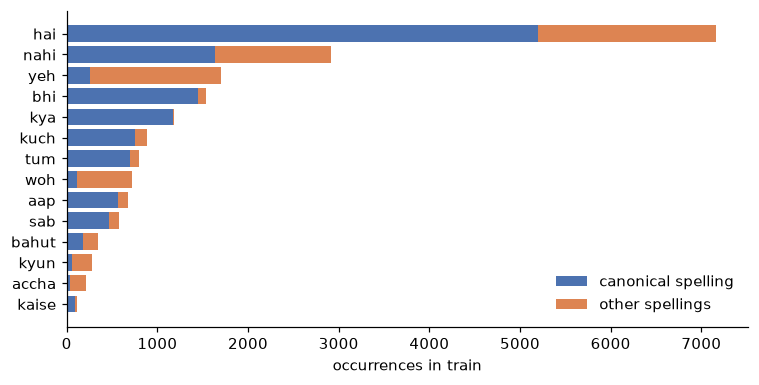

In [10]:
roman = Counter()
for t in raw["train"]["text"].map(clean_text):
    roman.update(w.lower() for w in words_of(t) if w.isascii() and w.isalpha())

n_tok, n_types = sum(roman.values()), len(roman)
hapax = sum(1 for c in roman.values() if c == 1)
top100 = sum(c for _, c in roman.most_common(100))
vocab_tbl = pd.DataFrame({"Roman word tokens": [n_tok], "distinct spellings": [n_types],
                          "% of spellings seen once": [round(100 * hapax / n_types, 1)],
                          "% of tokens covered by top 100": [round(100 * top100 / n_tok, 1)]})
tables["Roman vocabulary (train)"] = vocab_tbl
display(vocab_tbl)

rows = []
for canon, variants in NORM_GROUPS.items():
    cnt = {v: roman.get(v, 0) for v in variants}
    total = sum(cnt.values())
    rows.append({"group": canon, "total": total, "spellings used": sum(1 for c in cnt.values() if c),
                 "% in canonical form": round(100 * cnt[canon] / max(total, 1), 1),
                 "variants (count)": ", ".join(f"{v}:{c}" for v, c in sorted(cnt.items(), key=lambda x: -x[1]) if c)})
var_tbl = pd.DataFrame(rows).sort_values("total", ascending=False)
tables["Spelling variants of common function words (train)"] = var_tbl
display(var_tbl)

fig, ax = plt.subplots(figsize=(7, 3.6))
g = var_tbl.sort_values("total")
ax.barh(g["group"], g["total"] * g["% in canonical form"] / 100, color="#4c72b0", label="canonical spelling")
ax.barh(g["group"], g["total"] * (1 - g["% in canonical form"] / 100),
        left=g["total"] * g["% in canonical form"] / 100, color="#dd8452", label="other spellings")
ax.set_xlabel("occurrences in train"), ax.legend(frameon=False)
save("05_spelling_variants")

In [11]:
top20 = pd.DataFrame(roman.most_common(20), columns=["word", "count"])
top20["% of tokens"] = (100 * top20["count"] / n_tok).round(2)
tables["20 most common Roman words (train)"] = top20
top20.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
word,hai,ki,ko,ke,to,ka,se,me,ho,h,k,nahi,bhi,ye,aur,hi,kya,kar,modi,nhi
count,5206,3410,3378,2553,2541,2426,2178,2041,1864,1800,1742,1634,1446,1394,1371,1308,1173,1140,1022,995
% of tokens,2.88,1.89,1.87,1.41,1.41,1.34,1.21,1.13,1.03,1.0,0.96,0.9,0.8,0.77,0.76,0.72,0.65,0.63,0.57,0.55


**Read:** a large share of distinct spellings appear only once, which is the "no fixed spelling" problem in numbers. For common function words, several spellings are in real use. The conservative normaliser still gave no gain, so either the subword tokenizer already copes or the hand-written list is too narrow. If an abusive word ever shows up in the top-20 table, mask it before committing the table.

## 6. Facebook vs Twitter: how do the inputs differ?

Inputs only. This is the section that explains the out-of-domain drop. OOV rate is the share of word tokens in a split that never occur in train.

In [12]:
train_vocab = Counter()
for t in raw["train"]["text"].map(clean_text):
    train_vocab.update(w.lower() for w in words_of(t))


def oov_rate(df):
    toks = [w.lower() for t in df["text"].map(clean_text) for w in words_of(t)]
    return 100 * np.mean([w not in train_vocab for w in toks])


rows = []
for k, f in feats.items():
    r = {"split": NAMES[k], "rows": len(f), "median words": f["words"].median(), "% <=10 words": 100 * (f["words"] <= 10).mean(),
         "% Roman": 100 * (f["script_body"] == "roman").mean(), "% Devanagari": 100 * (f["script_body"] == "devanagari").mean(),
         "% mixed script": 100 * (f["script_body"] == "mixed").mean(), "% with #hashtag": 100 * f["hashtag"].mean(),
         "% with @mention": 100 * f["mention"].mean(), "% with URL": 100 * f["url"].mean(),
         "% with emoji": 100 * f["emoji"].mean(), "% repeated letters": 100 * f["repeat"].mean(),
         "mean caps share": f["caps_share"].mean()}
    if have_mix:
        r["mean Hindi share"] = f["hi_share"].mean()
    r["OOV % vs train"] = np.nan if k == "train" else oov_rate(raw[k])
    rows.append(r)
shift = pd.DataFrame(rows).round(2).set_index("split")
tables["Input comparison across splits"] = shift.reset_index()
display(shift.T)

split,Train,Dev,FB test,Twitter test
rows,11556.00,2812.00,970.00,1194.00
median words,16.00,17.00,20.00,17.00
% <=10 words,23.80,22.87,8.25,19.01
% Roman,75.37,75.89,67.84,40.62
% Devanagari,21.19,21.16,24.23,43.47
% mixed script,3.42,2.95,7.84,15.91
% with #hashtag,2.80,2.88,2.47,99.25
% with @mention,0.31,0.25,0.31,33.92
% with URL,1.45,1.42,0.41,12.06
% with emoji,6.20,5.80,7.53,7.71


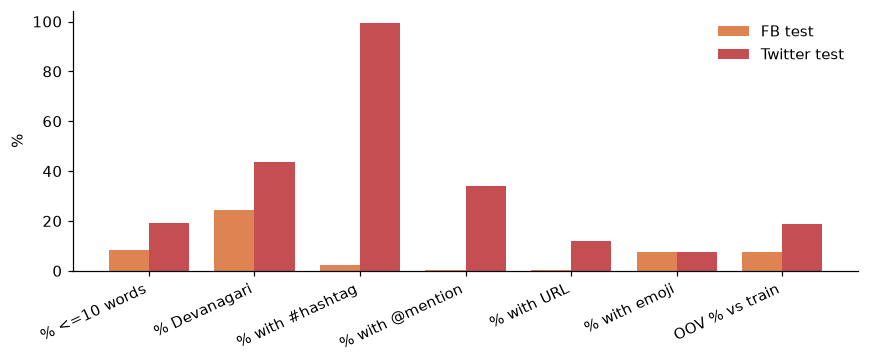

In [13]:
cols = ["% <=10 words", "% Devanagari", "% with #hashtag", "% with @mention", "% with URL", "% with emoji", "OOV % vs train"]
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(cols)); w = 0.38
ax.bar(x - w / 2, shift.loc["FB test", cols], w, color=COLORS["fb_test"], label="FB test")
ax.bar(x + w / 2, shift.loc["Twitter test", cols], w, color=COLORS["tw_test"], label="Twitter test")
ax.set_xticks(x), ax.set_xticklabels(cols, rotation=25, ha="right"), ax.set_ylabel("%"), ax.legend(frameon=False)
save("06_facebook_vs_twitter")

**Read:** compare the two coloured bars column by column. Whatever differs most (typically hashtags, mentions, URLs, vocabulary the model has never seen) is a concrete reason the Facebook-trained models lose accuracy on Twitter, and exactly the signals the drift monitor in Phase 7 should watch. This notebook shows *how the inputs differ*; it does not prove which difference causes the drop.

## 7. Do the models predict the same share of aggression on both platforms?

Uses only the saved sealed-test probabilities (no model is run). Each model's prediction rate at its own frozen dev threshold, averaged over seeds, against the true aggressive share of that test set.

In [14]:
import json
seal_path = ROOT / "reports" / "TEST_SEAL.json"
if seal_path.exists() and (ROOT / "reports" / "test_scores" / "fb.npz").exists():
    seal = json.loads(seal_path.read_text(encoding="utf-8"))
    rows = []
    for name, ts in (("fb", "FB test"), ("tw", "Twitter test")):
        z = np.load(ROOT / "reports" / "test_scores" / f"{name}.npz", allow_pickle=True)
        row = {"split": ts, "true aggressive %": round(100 * z["y"].mean(), 1)}
        for model, runs in seal["models"].items():
            row[f"{model} predicted %"] = round(100 * np.mean([(z[r] >= seal["thresholds"][r]).mean() for r in runs]), 1)
        rows.append(row)
    pred_tbl = pd.DataFrame(rows).set_index("split")
    tables["Predicted vs true aggressive share (test)"] = pred_tbl.reset_index()
    display(pred_tbl)
else:
    print("sealed-test scores not found; skipped")

,true aggressive %,hingbert predicted %,muril predicted %,xlmr predicted %,tfidf predicted %
split,,,,,
FB test,79.9,82.6,84.8,85.4,84.5
Twitter test,70.4,39.8,54.0,48.8,45.3


**Read:** on Facebook the models predict about as much aggression as there is (they were built to over-flag it: recall floor 0.90). If the predicted share on Twitter falls well below the true share, the models are under-calling aggression there, which matches the failed recall floor.

## 8. Write the summary (numbers only)

In [15]:
lines = ["# EDA summary", "", "Counts and shares only; generated by `notebooks/01_eda.ipynb`. Test sets are used for inputs only.", ""]
for name, tbl in tables.items():
    tbl.to_csv(TAB / (name.split("(")[0].strip().lower().replace(" ", "_").replace("%", "pct").replace("/", "_") + ".csv"), index=False)
    lines += [f"## {name}", "", tbl.to_markdown(index=False), ""]
(ROOT / "reports" / "eda_summary.md").write_text("\n".join(lines), encoding="utf-8")
print("wrote reports/eda_summary.md and", len(tables), "tables;", len(list(FIG.glob('*.png'))), "figures")

wrote reports/eda_summary.md and 12 tables; 7 figures


## What goes into the README

- One line each from sections 1, 3 and 6 (class balance, script share, how Twitter inputs differ).
- Figures `02_length_hist.png`, `05_spelling_variants.png` and `06_facebook_vs_twitter.png`.
- Spelling variation as the concrete evidence for "Hindi in Roman letters has no fixed spelling".